# Member C

## 01 Research Objective

The group project examines where respondents use AI in software development, how useful they find it and where they expect to use it in future. This objective compares the proportions of respondents who reported an increase, no change or a decrease in satisfaction when using AI across seven software development tasks.

## 02 Data Loading

| File | Contents |
|---|---|
| `survey_results_public.txt` | Survey responses, with one row per respondent (30,903 rows and 212 columns) |
| `survey_results_schema.txt` | Question wording and task definitions |

In [21]:
import pandas as pd

aisat_cols = [f"AISat_{i}" for i in range(1, 8)]
file_path = "../survey_results_public.txt"
df_c = pd.read_csv(file_path, usecols=["ResponseId", *aisat_cols])
print(df_c.shape)

(30903, 8)


## 03 Feature Selection

| Field | Description |
|---|---|
| `ResponseId` | Respondent identifier |
| `AISat_1` | Design |
| `AISat_2` | Implementation |
| `AISat_3` | Review |
| `AISat_4` | Debugging and refactoring |
| `AISat_5` | Documentation |
| `AISat_6` | Architecture exploration |
| `AISat_7` | Communication |

Selecting these eight columns retains all **30,903 respondents**.

In [22]:
task_names = {
    "AISat_1": "Design",
    "AISat_2": "Implementation",
    "AISat_3": "Review",
    "AISat_4": "Debugging/refactoring",
    "AISat_5": "Documentation",
    "AISat_6": "Architecture exploration",
    "AISat_7": "Communication"
}

## 04 Data Validation and Cleaning

For implementation (`AISat_2`), **11,921** respondents selected one of the five satisfaction categories and **18,982** had a missing response. Together they account for all **30,903** survey records.

In [23]:
valid = df_c[aisat_cols].notna().sum()
missing = df_c[aisat_cols].isna().sum()
missing_rate = missing / len(df_c) * 100

missing_table = pd.DataFrame({
    "Valid n": valid,
    "Missing n": missing,
    "Missing %": missing_rate.round(2)
})
missing_table = missing_table.rename(index=task_names)

display(missing_table.style.format({"Missing %": "{:.2f}%"}))
missing_table.to_csv("AISat_missingness_summary.csv", encoding="utf-8-sig")

,Valid n,Missing n,Missing %
Design,11768,19135,61.92%
Implementation,11921,18982,61.42%
Review,11768,19135,61.92%
Debugging/refactoring,11861,19042,61.62%
Documentation,11788,19115,61.85%
Architecture exploration,11741,19162,62.01%
Communication,11685,19218,62.19%


## 05 Statistical Analysis

In [24]:
categories = [
    "Greatly decreased",
    "Somewhat decreased",
    "No change",
    "Somewhat improved",
    "Greatly improved"
]

results = {}
for col in aisat_cols:
    counts = df_c[col].value_counts(dropna=False)
    counts = counts.reindex(categories, fill_value=0)
    results[col] = counts

summary = pd.DataFrame(results).T

display(summary.rename(index=task_names))

,Greatly decreased,Somewhat decreased,No change,Somewhat improved,Greatly improved
Design,682,854,4636,3375,2221
Implementation,976,1399,2377,4008,3161
Review,623,782,3856,3800,2707
Debugging/refactoring,511,735,2781,4230,3604
Documentation,545,610,3489,3286,3858
Architecture exploration,530,567,4207,3751,2686
Communication,1163,927,5783,2239,1573


| Summary category | Survey responses included |
|---|---|
| Improved | Greatly improved, Somewhat improved |
| No change | No change |
| Decreased | Greatly decreased, Somewhat decreased |

For implementation, 3,161 respondents reported greatly improved satisfaction and 4,008 reported somewhat improved satisfaction. Together they account for 7,169 of the 11,921 valid responses (**60.14%**). Each percentage in the table uses the valid response count for that task.

In [25]:
statistic = pd.DataFrame()
statistic["Decreased"] = summary["Greatly decreased"] + summary["Somewhat decreased"]
statistic["No change"] = summary["No change"]
statistic["Improved"] = summary["Somewhat improved"] + summary["Greatly improved"]

percentage_statistic = statistic.div(statistic.sum(axis=1), axis=0) * 100
plot_df = percentage_statistic.rename(index=task_names)
counts_and_shares = statistic.map("{:,}".format) + percentage_statistic.map(" ({:.2f}%)".format)
display(counts_and_shares.rename(index=task_names).rename_axis("Task / n (%)"))

,Decreased,No change,Improved
Task / n (%),,,
Design,"1,536 (13.05%)","4,636 (39.39%)","5,596 (47.55%)"
Implementation,"2,375 (19.92%)","2,377 (19.94%)","7,169 (60.14%)"
Review,"1,405 (11.94%)","3,856 (32.77%)","6,507 (55.29%)"
Debugging/refactoring,"1,246 (10.51%)","2,781 (23.45%)","7,834 (66.05%)"
Documentation,"1,155 (9.80%)","3,489 (29.60%)","7,144 (60.60%)"
Architecture exploration,"1,097 (9.34%)","4,207 (35.83%)","6,437 (54.82%)"
Communication,"2,090 (17.89%)","5,783 (49.49%)","3,812 (32.62%)"


**Matched responses for implementation**

For this comparison, each survey row supplies the same respondent's usefulness rating (`AIImpact_2`) and satisfaction rating (`AISat_2`). The table includes respondents who gave an applicable usefulness rating and one of the five satisfaction ratings. Its margins show how many respondents contributed to each comparison in Section 07.

In [26]:
implementation = pd.read_csv(file_path, usecols=["AIImpact_2", "AISat_2"]).dropna()
paired = implementation.loc[
    implementation["AIImpact_2"].ne("Not applicable") & implementation["AISat_2"].isin(categories)
]
usefulness = paired["AIImpact_2"].isin(["Useful", "Very useful"]).map(
    {True: "Useful or very useful", False: "Other applicable rating"}
)
satisfaction = paired["AISat_2"].isin(["Somewhat improved", "Greatly improved"]).map(
    {True: "Improved", False: "Unchanged or decreased"}
)
implementation_counts = pd.crosstab(
    usefulness.rename("Perceived usefulness"), satisfaction.rename("Satisfaction"),
    margins=True, margins_name="Total"
)
display(implementation_counts)

Satisfaction,Improved,Unchanged or decreased,Total
Perceived usefulness,,,
Other applicable rating,509,1983,2492
Useful or very useful,6555,2377,8932
Total,7064,4360,11424


In [27]:
# Check that the three categories account for all valid responses to each task.
print((statistic.sum(axis=1) == valid).all())

# Check that valid and missing responses account for all respondents.
print((valid + missing == len(df_c)).all())

# Check that each task's percentages sum to 100% within the rounding tolerance.
print(((percentage_statistic.sum(axis=1) - 100).abs() < 0.02).all())

True
True
True


## 06 Data Visualisation

Each bar represents one task. Red shows the share who reported decreased satisfaction, grey shows no change and green shows improved satisfaction.

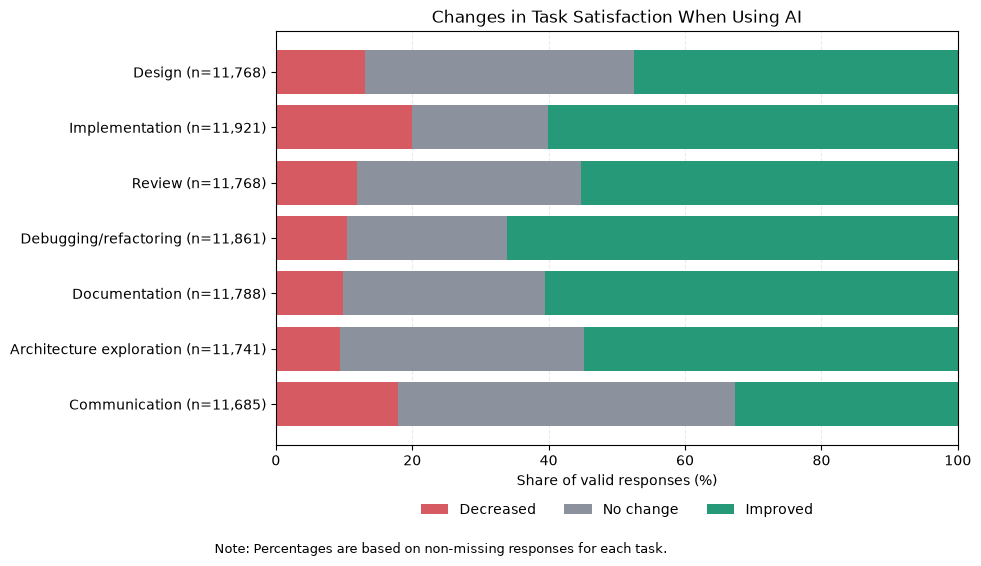

In [28]:
import matplotlib.pyplot as plt

valid_by_task = valid.rename(index=task_names)

task_labels = [
    f"{task} (n={valid_by_task.loc[task]:,})"
    for task in plot_df.index
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    plot_df.index, plot_df["Decreased"],
    color="#D65A61", label="Decreased"
)

ax.barh(
    plot_df.index, plot_df["No change"],
    left=plot_df["Decreased"],
    color="#8B929D", label="No change"
)

ax.barh(
    plot_df.index, plot_df["Improved"],
    left=plot_df["Decreased"] + plot_df["No change"],
    color="#269A78", label="Improved"
)

ax.set_xlim(0, 100)
ax.set_xlabel("Share of valid responses (%)")

ax.set_yticks(range(len(plot_df.index)))
ax.set_yticklabels(task_labels)
ax.invert_yaxis()

ax.set_title("Changes in Task Satisfaction When Using AI")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.11),
    ncol=3,
    frameon=False
)

ax.set_axisbelow(True)
ax.grid(axis="x", linestyle="--", alpha=0.25)

fig.text(
    0.5, 0.04,
    "Note: Percentages are based on non-missing responses for each task.",
    ha="center",
    fontsize=9
)

fig.subplots_adjust(
    left=0.35,
    right=0.97,
    top=0.91,
    bottom=0.22
)

plt.savefig(
    "AISat_100pct_stacked_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 07 Results and Discussion

### Main Findings

In **five of the seven tasks**, more than half of the valid responses reported improved satisfaction. Debugging and refactoring had the highest improvement rate (**66.05%**), while communication had the lowest (**32.62%**), a difference of **33.43 percentage points**. For communication, the most common response was no change (**49.49%**).

Implementation showed a different pattern. Among its **11,921** valid responses, **60.14%** reported improved satisfaction, but **19.92%** reported decreased satisfaction, the highest decrease rate among the seven tasks. For the same task, some respondents reported higher satisfaction when using AI and others reported lower satisfaction.

### Comparison with Member B

Three tasks were selected to highlight differences and similarities between perceived usefulness and satisfaction improvement. Implementation ranked first for perceived usefulness in Member B's results but third for satisfaction improvement. Debugging and refactoring had the highest satisfaction improvement rate, while communication ranked last on both measures.

The table compares the three selected tasks using each question's own valid responses. Member B's usefulness counts come from `df_impct_summary` in `member_B_real.ipynb`.

| Task | Useful or very useful (Member B) | Improved satisfaction (Member C) |
|---|---:|---:|
| Implementation | 9,360 / 12,052 (77.66%) | 7,169 / 11,921 (60.14%) |
| Debugging/refactoring | 9,103 / 11,924 (76.34%) | 7,834 / 11,861 (66.05%) |
| Communication | 4,342 / 10,077 (43.09%) | 3,812 / 11,685 (32.62%) |

For implementation, **11,424** respondents gave valid, applicable answers to both questions. Among them, **8,932** rated AI as useful or very useful. Of these 8,932 respondents, **6,555 (73.39%)** reported improved satisfaction, while **2,377 (26.61%)** reported unchanged or decreased satisfaction.

This suggests that finding AI useful does not always mean feeling more satisfied with the task. Of the **11,921** respondents who gave a valid satisfaction rating for implementation, **11,424** also gave an applicable usefulness rating and formed the paired sample.

### Limitations

There are some limitations to this analysis. Although the original dataset contained **30,903 survey records**, only **11,685 to 11,921 valid responses** were available for each satisfaction question. The AISat questions were only shown to respondents who selected certain AI tools used at work, and answering them was optional. Therefore, missing values may result from survey skip logic or unanswered questions.

The percentages were calculated using each task's valid responses, so the findings may not represent all survey participants. In addition, the results are based on developers' self-reported satisfaction rather than direct measurements of task performance. Therefore, this analysis cannot establish that AI directly causes higher satisfaction or improves actual work efficiency.